# 04 Segmentation (BQ4): Python version

**BQ4:** Which groups of customers and products behave differently, and how much revenue does each group bring?

- **Part A, customers:** RFM scores and rule-based segments, then k-means clustering on recency, frequency and monetary value.
- **Part B, products:** ABC (Pareto) classification, then k-means clustering on sales, reach, price and seasonality.

Window: **Year 2** (1 Dec 2010 – 30 Nov 2011), the last twelve complete months (T10).
Same questions, data and definitions as `04_segmentation_r.ipynb`; the RFM scores, segments and ABC classes must match exactly.

## Setup and data

In [33]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROC = ROOT / "data" / "processed"
FIG = ROOT / "reports" / "figures"
DASH = ROOT / "reports" / "dashboard_data"
FIG.mkdir(parents=True, exist_ok=True)
DASH.mkdir(parents=True, exist_ok=True)

START, END = "2010-12-01", "2011-12-01"   # Year 2 window; END is also the RFM reference date
SEED = 42
K_RANGE = range(2, 9)

sales = pd.read_parquet(PROC / "sales_clean.parquet")
cancels = pd.read_parquet(PROC / "cancellations.parquet")
prod = sales.loc[(sales["line_type"] == "product")                       # T6
                 & (sales["invoice_date"] >= START) & (sales["invoice_date"] < END)].copy()
canc = cancels.loc[(cancels["line_type"] == "product")                   # T5
                   & (cancels["invoice_date"] >= START) & (cancels["invoice_date"] < END)].copy()
del sales, cancels
print(f"Year 2 product lines: {len(prod):,}   cancellation lines: {len(canc):,}")
print(f"Gross £{prod['revenue'].sum():,.0f}   cancelled £{-canc['revenue'].sum():,.0f}   "
      f"net £{prod['revenue'].sum() + canc['revenue'].sum():,.0f}")

Year 2 product lines: 497,787   cancellation lines: 8,321
Gross £9,632,728   cancelled £301,810   net £9,330,919


# Part A: Customer segmentation

| Measure | Definition |
|---|---|
| `recency_days` | Days from the last purchase date to 1 Dec 2011 (minimum 1) |
| `frequency` | Number of distinct purchase days |
| `monetary` | Net revenue: gross product sales minus product cancellations |

Identified customers only (T7). Customers with zero or negative net revenue (everything cancelled) are excluded.

In [34]:
ref = pd.Timestamp(END)
y2 = prod.loc[prod["has_customer"]]
c2 = canc.loc[canc["customer_id"].notna()]

cust = y2.groupby("customer_id").agg(last_buy=("date", "max"), frequency=("date", "nunique"),
                                     gross=("revenue", "sum"), uk_share=("is_uk", "mean"))
cust["cancelled"] = (-c2.groupby("customer_id")["revenue"].sum()).reindex(cust.index).fillna(0)
cust["monetary"] = (cust["gross"] - cust["cancelled"]).round(2)   # to the penny: removes float residue
cust["recency_days"] = (ref - cust["last_buy"]).dt.days
n_all = len(cust)
cust = cust.loc[cust["monetary"] > 0].sort_index()
print(f"Customers in Year 2: {n_all:,}   used: {len(cust):,} (dropped {n_all - len(cust)} with net revenue <= 0)")
cust[["recency_days", "frequency", "monetary"]].describe().T

Customers in Year 2: 4,293   used: 4,280 (dropped 13 with net revenue <= 0)


,count,mean,std,min,25%,50%,75%,max
recency_days,"4,280.000",91.508,98.682,1.000,16.000,49.000,146.000,365.000
frequency,"4,280.000",3.729,5.713,1.000,1.000,2.000,4.000,125.000
monetary,"4,280.000","1,853.150","8,031.571",2.900,294.803,634.480,"1,544.097","267,050.000"


## A1. RFM scores and segments

Each measure is scored 1–5 by quintile (5 = best: most recent, most frequent, highest value).
Ties are broken by customer ID, so Python and R give identical scores.

| Segment | Rule | Meaning |
|---|---|---|
| Champions | R ≥ 4 and F ≥ 4 | Recent and frequent |
| Loyal | R ≥ 3 and F ≥ 3 (not Champions) | Regular buyers |
| New or promising | R ≥ 4 and F ≤ 2 | Recent but few purchases yet |
| Needs attention | R = 3 and F ≤ 2 | Fading occasional buyers |
| At risk | R ≤ 2 and F ≥ 3 | Used to buy often, now quiet |
| Hibernating | R ≤ 2 and F ≤ 2 | Rare and long ago |

In [35]:
def quintile(x):
    """Score 1-5 by rank; ties broken by row order (customer ID)."""
    return np.ceil(5 * x.rank(method="first") / len(x)).astype(int)

cust["R"] = quintile(-cust["recency_days"])
cust["F"] = quintile(cust["frequency"])
cust["M"] = quintile(cust["monetary"])

R, F = cust["R"], cust["F"]
cust["rfm_segment"] = np.select(
    [(R >= 4) & (F >= 4), (R >= 3) & (F >= 3), (R >= 4) & (F <= 2), (R == 3) & (F <= 2), (R <= 2) & (F >= 3)],
    ["Champions", "Loyal", "New or promising", "Needs attention", "At risk"], default="Hibernating")

SEG_ORDER = ["Champions", "Loyal", "New or promising", "Needs attention", "At risk", "Hibernating"]
seg = (cust.groupby("rfm_segment")
       .agg(customers=("monetary", "size"), revenue=("monetary", "sum"),
            median_recency=("recency_days", "median"), median_frequency=("frequency", "median"),
            median_monetary=("monetary", "median"))
       .reindex(SEG_ORDER))
seg.insert(1, "customer_share", seg["customers"] / seg["customers"].sum())
seg.insert(3, "revenue_share", seg["revenue"] / seg["revenue"].sum())
print("Score check (each score 1-5 should hold about 20% of customers):")
print(cust[["R", "F", "M"]].apply(lambda s: s.value_counts().sort_index()).T, "\n")
seg

Score check (each score 1-5 should hold about 20% of customers):
     1    2    3    4    5
R  856  856  856  856  856
F  856  856  856  856  856
M  856  856  856  856  856 



,customers,customer_share,revenue,revenue_share,median_recency,median_frequency,median_monetary
rfm_segment,,,,,,,
Champions,1087,0.254,"5,400,466.230",0.681,11.000,6.000,"2,128.830"
Loyal,814,0.190,"1,065,952.610",0.134,38.000,3.000,817.795
New or promising,333,0.078,"136,092.740",0.017,17.000,1.000,301.290
Needs attention,334,0.078,"148,961.740",0.019,51.000,1.000,324.520
At risk,667,0.156,"737,698.680",0.093,135.000,3.000,711.410
Hibernating,1045,0.244,"442,310.350",0.056,225.000,1.000,253.050


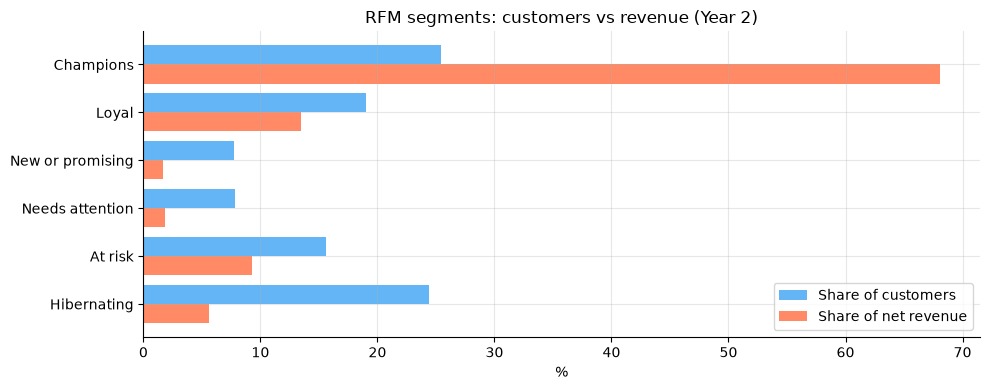

In [36]:
fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(seg))
ax.barh(y - 0.2, seg["customer_share"] * 100, height=0.4, label="Share of customers", color="#64B5F6")
ax.barh(y + 0.2, seg["revenue_share"] * 100, height=0.4, label="Share of net revenue", color="#FF8A65")
ax.set_yticks(y, seg.index); ax.invert_yaxis(); ax.set_xlabel("%")
ax.set_title("RFM segments: customers vs revenue (Year 2)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "bq4_rfm_segments.png", dpi=150); plt.show()

## A2. K-means clustering: choosing the number of clusters

Inputs: log(recency), log(frequency), log(monetary), each standardised (mean 0, SD 1).
The logs reduce the heavy right skew so that a few very large customers do not form clusters on their own.

- **Elbow:** total within-cluster sum of squares; look for the point where adding clusters stops helping much.
- **Silhouette:** how well each customer fits its own cluster compared with the nearest other cluster (−1 to 1; higher is better).

Each k uses 50 random starts and keeps the best solution, so Python and R should reach the same optimum.

In [37]:
def standardise(df):
    return (df - df.mean()) / df.std(ddof=0)

Xc = standardise(np.log(cust[["recency_days", "frequency", "monetary"]]))

def k_selection(X):
    rows = []
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
        rows.append({"k": k, "within_ss": km.inertia_, "silhouette": silhouette_score(X, km.labels_)})
    return pd.DataFrame(rows).set_index("k")

ksel_c = k_selection(Xc.values)
ksel_c

,within_ss,silhouette
k,,
2,"6,433.209",0.427
3,"4,960.021",0.327
4,"3,937.372",0.337
5,"3,365.099",0.317
6,"2,906.942",0.311
7,"2,637.160",0.311
8,"2,420.085",0.281


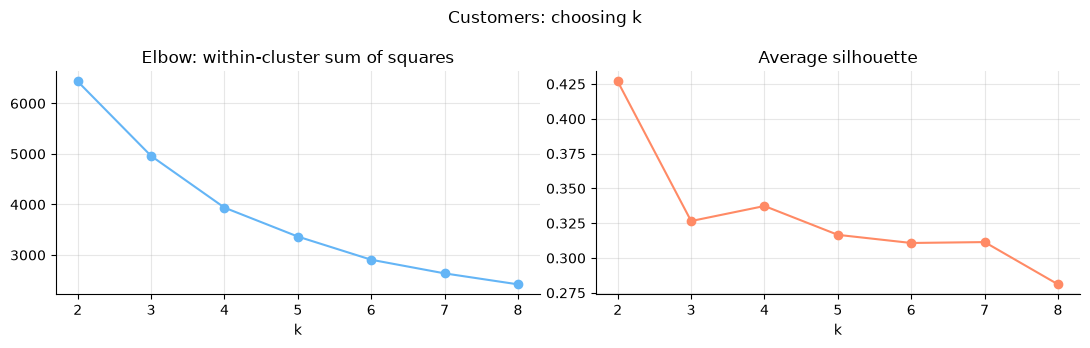

In [38]:
def plot_k(ksel, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    axes[0].plot(ksel.index, ksel["within_ss"], marker="o", color="#64B5F6")
    axes[0].set_title("Elbow: within-cluster sum of squares"); axes[0].set_xlabel("k")
    axes[1].plot(ksel.index, ksel["silhouette"], marker="o", color="#FF8A65")
    axes[1].set_title("Average silhouette"); axes[1].set_xlabel("k")
    fig.suptitle(title); fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

plot_k(ksel_c, "Customers: choosing k", FIG / "bq4_customer_k.png")

## A3. Final customer clusters

`K_CUST` is chosen from the elbow and silhouette charts together with how easy the clusters are to explain.
Clusters are numbered by average net revenue (cluster 1 = highest), so the numbering is the same in Python and R.

In [39]:
K_CUST = 4

def fit_final(X, k, order_by):
    """Fit k-means and renumber clusters 1..k by descending mean of `order_by`."""
    km = KMeans(n_clusters=k, n_init=50, random_state=SEED).fit(X)
    rank = pd.Series(order_by.values).groupby(km.labels_).mean().rank(ascending=False, method="first").astype(int)
    return pd.Series(km.labels_, index=order_by.index).map(rank), km.inertia_

cust["cluster"], wss_c = fit_final(Xc.values, K_CUST, cust["monetary"])
print(f"k = {K_CUST}   within-cluster SS: {wss_c:,.2f}\n")

prof_c = (cust.groupby("cluster")
          .agg(customers=("monetary", "size"), revenue=("monetary", "sum"),
               median_recency=("recency_days", "median"), median_frequency=("frequency", "median"),
               median_monetary=("monetary", "median"), uk_share=("uk_share", "mean")))
prof_c.insert(1, "customer_share", prof_c["customers"] / prof_c["customers"].sum())
prof_c.insert(3, "revenue_share", prof_c["revenue"] / prof_c["revenue"].sum())
prof_c

k = 4   within-cluster SS: 3,937.37



,customers,customer_share,revenue,revenue_share,median_recency,median_frequency,median_monetary,uk_share
cluster,,,,,,,,
1,739,0.173,"5,166,004.960",0.651,9.000,8.000,"3,304.130",0.888
2,1234,0.288,"1,897,913.110",0.239,55.500,3.000,"1,183.230",0.900
3,786,0.184,"368,586.000",0.046,15.000,2.000,396.645,0.916
4,1521,0.355,"498,978.280",0.063,179.000,1.000,272.070,0.911


Customers by cluster and RFM segment:
rfm_segment  Champions  Loyal  New or promising  Needs attention  At risk  Hibernating   All
cluster                                                                                     
1                  701     33                 1                0        4            0   739
2                  270    467                 8               34      421           34  1234
3                  116    283               320               67        0            0   786
4                    0     31                 4              233      242         1011  1521
All               1087    814               333              334      667         1045  4280


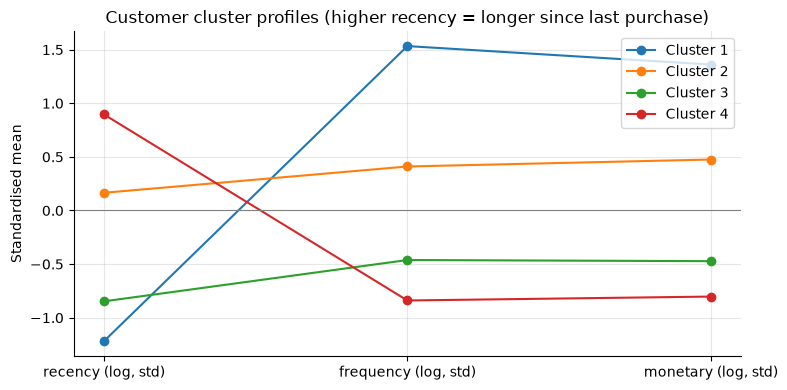

,"recency (log, std)","frequency (log, std)","monetary (log, std)"
cluster,,,
1,-1.219,1.533,1.361
2,0.165,0.410,0.475
3,-0.847,-0.462,-0.472
4,0.896,-0.839,-0.803


In [40]:
print("Customers by cluster and RFM segment:")
print(pd.crosstab(cust["cluster"], pd.Categorical(cust["rfm_segment"], SEG_ORDER),
                  colnames=["rfm_segment"], margins=True))

centres = Xc.groupby(cust["cluster"]).mean()
centres.columns = ["recency (log, std)", "frequency (log, std)", "monetary (log, std)"]
fig, ax = plt.subplots(figsize=(8, 4))
for c, row in centres.iterrows():
    ax.plot(row.index, row.values, marker="o", label=f"Cluster {c}")
ax.axhline(0, color="grey", lw=0.8); ax.set_ylabel("Standardised mean")
ax.set_title("Customer cluster profiles (higher recency = longer since last purchase)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "bq4_customer_clusters.png", dpi=150); plt.show()
centres.round(3)

# Part B: Product segmentation

All Year 2 product lines (with or without a customer ID), grouped by stock code.

| Measure | Definition |
|---|---|
| `net` | Gross sales minus cancellations of that product |
| `customers` | Distinct identified customers who bought it |
| `orders` | Distinct invoices containing it |
| `price` | Median unit price |
| `q4_share` | Share of gross sales in October–December (seasonality) |
| `cancel_rate` | Cancelled value ÷ gross sales |

In [41]:
prod["q4_rev"] = prod["revenue"].where(prod["invoice_date"].dt.month >= 10, 0.0)
items = prod.groupby("stock_code").agg(product=("product_name", "first"),
                                       gross=("revenue", "sum"), q4_rev=("q4_rev", "sum"),
                                       orders=("invoice", "nunique"), customers=("customer_id", "nunique"),
                                       price=("price", "median"))
items["cancelled"] = (-canc.groupby("stock_code")["revenue"].sum()).reindex(items.index).fillna(0)
items["net"] = (items["gross"] - items["cancelled"]).round(2)
items["q4_share"] = items["q4_rev"] / items["gross"]
items["cancel_rate"] = (items["cancelled"] / items["gross"]).clip(0, 1)
n_items = len(items)
items = items.loc[items["net"] > 0]
print(f"Products sold in Year 2: {n_items:,}   with positive net revenue: {len(items):,}")
items[["net", "orders", "customers", "price", "q4_share", "cancel_rate"]].describe().T

Products sold in Year 2: 3,905   with positive net revenue: 3,896


,count,mean,std,min,25%,50%,75%,max
net,"3,896.000","2,395.080","6,002.321",0.420,120.573,646.320,"2,085.535","158,569.320"
orders,"3,896.000",126.514,185.733,1.000,15.000,61.500,158.000,"2,132.000"
customers,"3,896.000",66.152,88.427,0.000,7.000,33.000,90.000,873.000
price,"3,896.000",3.591,6.856,0.040,1.250,2.100,4.130,165.000
q4_share,"3,896.000",0.371,0.277,0.000,0.177,0.307,0.505,1.000
cancel_rate,"3,896.000",0.021,0.068,0.000,0.000,0.000,0.014,0.958


## B1. ABC classification

Products are ranked by net revenue. **A** = products that together make the first 80% of revenue,
**B** = the next 15%, **C** = the last 5%. Ties are ordered by stock code.

In [42]:
items = (items.reset_index()
         .sort_values(["net", "stock_code"], ascending=[False, True])
         .set_index("stock_code"))
items["cum_share"] = items["net"].cumsum() / items["net"].sum()
items["abc"] = np.select([items["cum_share"] <= 0.80, items["cum_share"] <= 0.95], ["A", "B"], default="C")

abc = items.groupby("abc").agg(products=("net", "size"), revenue=("net", "sum"),
                                median_price=("price", "median"), median_customers=("customers", "median"))
abc.insert(1, "product_share", abc["products"] / abc["products"].sum())
abc.insert(3, "revenue_share", abc["revenue"] / abc["revenue"].sum())
abc

,products,product_share,revenue,revenue_share,median_price,median_customers
abc,,,,,,
A,837,0.215,"7,462,445.420",0.800,2.550,166.000
B,979,0.251,"1,402,191.030",0.150,1.650,64.000
C,2080,0.534,"466,596.690",0.050,2.100,8.000


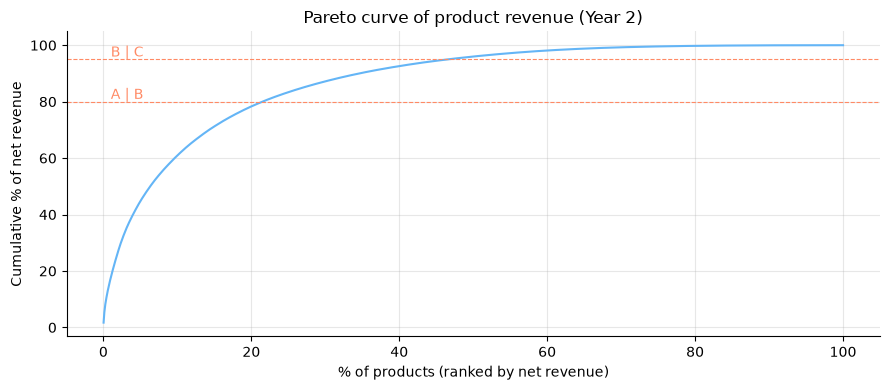

In [43]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(1, len(items) + 1) / len(items) * 100
ax.plot(x, items["cum_share"].values * 100, color="#64B5F6")
for cut, lab in [(80, "A | B"), (95, "B | C")]:
    ax.axhline(cut, color="#FF8A65", lw=0.8, ls="--"); ax.text(1, cut + 1, lab, color="#FF8A65")
ax.set_xlabel("% of products (ranked by net revenue)"); ax.set_ylabel("Cumulative % of net revenue")
ax.set_title("Pareto curve of product revenue (Year 2)")
fig.tight_layout(); fig.savefig(FIG / "bq4_abc_pareto.png", dpi=150); plt.show()

## B2. Product clustering

Products with at least 20 orders (enough history for a stable profile).
Inputs: log(net revenue), log(1 + customers), log(price), and Q4 share, each standardised.
The cancellation rate is reported in the profiles but not used for clustering, because most products have a rate of 0
and a few extreme values would dominate the distances.

Products clustered: 2,798


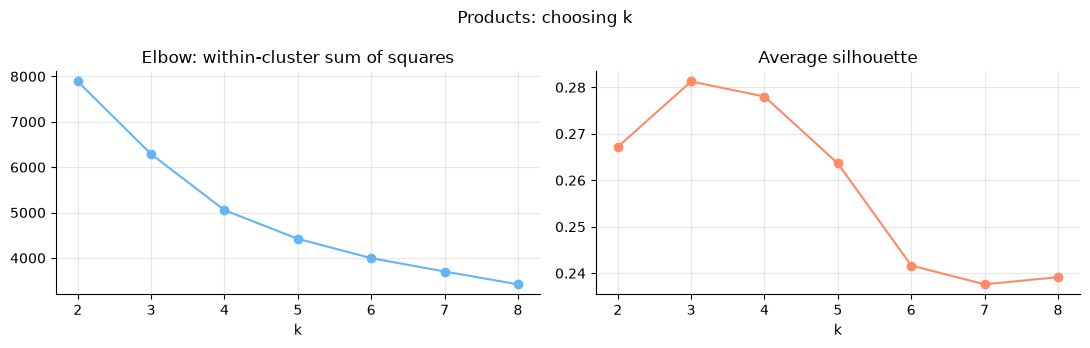

,within_ss,silhouette
k,,
2,"7,887.903",0.267
3,"6,288.291",0.281
4,"5,053.694",0.278
5,"4,421.695",0.264
6,"3,996.809",0.242
7,"3,702.198",0.238
8,"3,419.216",0.239


In [44]:
pc = items.loc[items["orders"] >= 20].sort_index()
Xp = standardise(pd.DataFrame({"log_net": np.log(pc["net"]), "log_customers": np.log1p(pc["customers"]),
                               "log_price": np.log(pc["price"]), "q4_share": pc["q4_share"]}))
print(f"Products clustered: {len(pc):,}")
ksel_p = k_selection(Xp.values)
plot_k(ksel_p, "Products: choosing k", FIG / "bq4_product_k.png")
ksel_p

In [45]:
K_PROD = 4
pc = pc.copy()
pc["cluster"], wss_p = fit_final(Xp.values, K_PROD, pc["net"])
print(f"k = {K_PROD}   within-cluster SS: {wss_p:,.2f}\n")

prof_p = (pc.groupby("cluster")
          .agg(products=("net", "size"), revenue=("net", "sum"), median_net=("net", "median"),
               median_customers=("customers", "median"), median_price=("price", "median"),
               mean_q4_share=("q4_share", "mean"), mean_cancel_rate=("cancel_rate", "mean"),
               share_class_A=("abc", lambda s: (s == "A").mean())))
prof_p.insert(1, "product_share", prof_p["products"] / prof_p["products"].sum())
prof_p.insert(3, "revenue_share", prof_p["revenue"] / prof_p["revenue"].sum())
prof_p

k = 4   within-cluster SS: 5,053.69



,products,product_share,revenue,revenue_share,median_net,median_customers,median_price,mean_q4_share,mean_cancel_rate,share_class_A
cluster,,,,,,,,,,
1,881,0.315,"7,188,101.440",0.778,"4,930.850",148.000,2.950,0.288,0.022,0.799
2,470,0.168,"902,748.570",0.098,"1,320.970",57.000,2.080,0.752,0.021,0.198
3,799,0.286,"787,023.110",0.085,762.830,55.000,0.830,0.248,0.014,0.039
4,648,0.232,"356,236.910",0.039,422.130,17.000,2.950,0.293,0.019,0.008


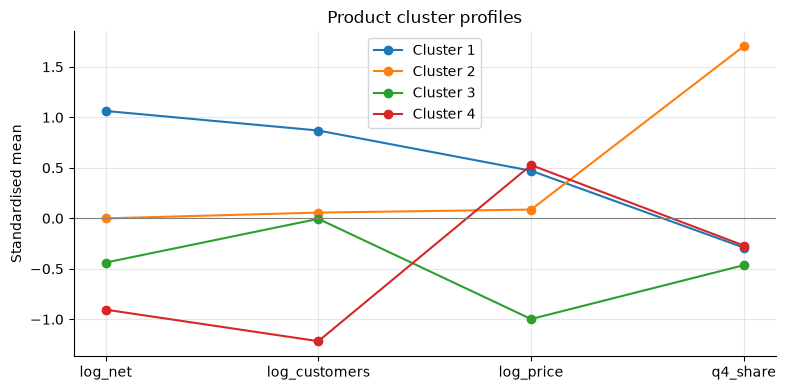

Example products per cluster (highest net revenue):
  Cluster 1: REGENCY CAKESTAND 3 TIER; PARTY BUNTING; WHITE HANGING HEART T-LIGHT HO
  Cluster 2: ROTATING SILVER ANGELS T-LIGHT; RED WOOLLY HOTTIE WHITE HEART.; HAND WARMER BIRD DESIGN
  Cluster 3: PACK OF 12 LONDON TISSUES; PLACE SETTING WHITE HEART; BROCADE RING PURSE
  Cluster 4: CAMOUFLAGE DESIGN TEDDY; CHILDRENS CUTLERY RETROSPOT RE; VINTAGE BLUE KITCHEN CABINET


In [46]:
centres_p = Xp.groupby(pc["cluster"]).mean()
fig, ax = plt.subplots(figsize=(8, 4))
for c, row in centres_p.iterrows():
    ax.plot(row.index, row.values, marker="o", label=f"Cluster {c}")
ax.axhline(0, color="grey", lw=0.8); ax.set_ylabel("Standardised mean")
ax.set_title("Product cluster profiles"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "bq4_product_clusters.png", dpi=150); plt.show()
print("Example products per cluster (highest net revenue):")
for c in range(1, K_PROD + 1):
    top = pc.loc[pc["cluster"] == c].nlargest(3, "net")
    print(f"  Cluster {c}: " + "; ".join(top["product"].astype(str).str[:30]))

## Export for the dashboard

In [47]:
seg_out = seg.reset_index().rename(columns={"index": "rfm_segment"})
seg_out.round(4).to_csv(DASH / "customer_rfm_segments.csv", index=False)

prof_c.reset_index().round(4).to_csv(DASH / "customer_clusters.csv", index=False)

cust_out = cust[["recency_days", "frequency", "monetary", "R", "F", "M", "rfm_segment", "cluster"]].reset_index()
cust_out["monetary"] = cust_out["monetary"].round(2)
cust_out.to_csv(DASH / "customer_rfm.csv", index=False)

abc.reset_index().round(4).to_csv(DASH / "product_abc.csv", index=False)
prof_p.reset_index().round(4).to_csv(DASH / "product_clusters.csv", index=False)

for f in ["customer_rfm_segments.csv", "customer_clusters.csv", "customer_rfm.csv",
          "product_abc.csv", "product_clusters.csv"]:
    print(f"{f:<28} {len(pd.read_csv(DASH / f)):>6,} rows")

customer_rfm_segments.csv         6 rows
customer_clusters.csv             4 rows
customer_rfm.csv              4,280 rows
product_abc.csv                   3 rows
product_clusters.csv              4 rows
